# Step 2: Choose Your Topic and Dataset
**Domain:** Population and Society  
**Dataset:** UCI Adult (Census Income)  
**Source:** https://archive.ics.uci.edu/dataset/2/adult

To run every cell, choose **Runtime → Run all**.

## 1. Download the dataset from UCI

In [1]:
# --- Import libraries ---
import io              # lets us treat downloaded bytes like a file
import zipfile         # opens the .zip file that UCI provides
import urllib.request  # downloads the file from the web
import pandas as pd    # loads and analyses the table

# Direct download link for the dataset on the UCI website
URL = "https://archive.ics.uci.edu/static/public/2/adult.zip"

# The raw files have no header row, so we supply the 15 column names ourselves
COLUMNS = ["age", "workclass", "fnlwgt", "education", "education_num",
           "marital_status", "occupation", "relationship", "race", "sex",
           "capital_gain", "capital_loss", "hours_per_week", "native_country",
           "income"]

# Download the zip into memory and open it
z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(URL).read()))
print("Files inside the zip:", z.namelist())

def read_part(name, skip):
    """Read one file from the zip into a DataFrame.
    skip = number of lines to skip at the top (adult.test has 1 junk line)."""
    return pd.read_csv(
        io.TextIOWrapper(z.open(name)),  # open the file inside the zip as text
        header=None,                     # the file has no header row
        names=COLUMNS,                   # use our own column names
        skiprows=skip,                   # skip the junk first line if needed
        skipinitialspace=True,           # remove the space after each comma
        na_values="?",                   # UCI marks missing values with '?'
    )

# UCI splits the data into a training file and a test file.
# We combine them so we have the full dataset (48,842 rows).
df = pd.concat([read_part("adult.data", 0), read_part("adult.test", 1)],
               ignore_index=True)       # renumber rows from 0

# In adult.test the labels are written '>50K.' and '<=50K.' (with a full stop).
# Remove the full stop so both files use the same two labels.
df["income"] = df["income"].str.rstrip(".")

# Save the original (uncleaned) data as a CSV for GitHub and Moodle
df.to_csv("adult_raw.csv", index=False)
print("Saved adult_raw.csv")

# Show the first 5 rows to check it loaded correctly
df.head()

Files inside the zip: ['Index', 'adult.data', 'adult.names', 'adult.test', 'old.adult.names']
Saved adult_raw.csv


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 2. Check the dataset size (raw)

In [2]:
# Number of rows and columns before any cleaning
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")

# Data type and count of non-missing values in every column
df.info()

Rows: 48,842   Columns: 15
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       46043 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education_num   48842 non-null  int64 
 5   marital_status  48842 non-null  object
 6   occupation      46033 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital_gain    48842 non-null  int64 
 11  capital_loss    48842 non-null  int64 
 12  hours_per_week  48842 non-null  int64 
 13  native_country  47985 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


## 3. What each column means

| Column | Type | Meaning |
|---|---|---|
| age | Numeric | Age of the person in years |
| workclass | Categorical | Type of employer (private, self-employed, government, etc.) |
| fnlwgt | Numeric | **Census sampling weight**: roughly how many people in the US population this record represents. It describes the sample, **not a characteristic of the person**, so it is usually left out of analysis and PCA. |
| education | Categorical | Highest education level as text (e.g. Bachelors, HS-grad) |
| education_num | Numeric | The same education level as a number (1 = Preschool … 16 = Doctorate). **It holds the same information as `education`**, so only one of the two should be used in modelling and PCA. |
| marital_status | Categorical | Marital status (married, never married, divorced, etc.) |
| occupation | Categorical | Type of job (e.g. Tech-support, Sales, Craft-repair) |
| relationship | Categorical | Role in the household (husband, wife, own-child, etc.) |
| race | Categorical | Race recorded in the census |
| sex | Categorical | Male or Female |
| capital_gain | Numeric | Income from investments (e.g. selling shares), in US dollars |
| capital_loss | Numeric | Losses from investments, in US dollars |
| hours_per_week | Numeric | Hours worked per week |
| native_country | Categorical | Country of birth |
| income | Categorical (target) | Whether yearly income is `<=50K` or `>50K` US dollars |

## 4. Categorical and numeric columns (needed for encoding and PCA in Task 3)

In [3]:
# Text columns are stored with dtype 'object' -> these are categorical
cat_cols = df.select_dtypes(include="object").columns.tolist()

# Integer/float columns -> these are numeric
num_cols = df.select_dtypes(include="number").columns.tolist()

print(f"Categorical ({len(cat_cols)}):", cat_cols)
print(f"Numeric ({len(num_cols)}):", num_cols)

Categorical (9): ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country', 'income']
Numeric (6): ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']


## 5. Missing values (needed for data preparation in Task 1)

In [4]:
# Count missing values (NaN) in each column
missing = df.isna().sum()

# Keep only the columns that actually have missing values
missing = missing[missing > 0]

# Show the count and the percentage of all rows
print(pd.DataFrame({"missing": missing,
                    "percent": (missing / len(df) * 100).round(2)}))

# A row is counted once even if it has several missing values
rows_with_missing = df.isna().any(axis=1).sum()
print("Rows with at least one missing value:", rows_with_missing)

                missing  percent
workclass          2799     5.73
occupation         2809     5.75
native_country      857     1.75
Rows with at least one missing value: 3620


## 6. Outliers (IQR rule)

In [5]:
# IQR rule: a value is an outlier if it is more than 1.5 x IQR
# below the 1st quartile (Q1) or above the 3rd quartile (Q3).
outlier_counts = {}                     # store results for the summary later
for c in num_cols:                      # check every numeric column
    q1, q3 = df[c].quantile([0.25, 0.75])   # 25th and 75th percentiles
    iqr = q3 - q1                           # interquartile range
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr   # outlier limits
    n = ((df[c] < lower) | (df[c] > upper)).sum()   # values outside limits
    outlier_counts[c] = n
    print(f"{c:15s} outliers = {n:6,}   min = {df[c].min():,}   max = {df[c].max():,}")

age             outliers =    216   min = 17   max = 90
fnlwgt          outliers =  1,453   min = 12,285   max = 1,490,400
education_num   outliers =  1,794   min = 1   max = 16
capital_gain    outliers =  4,035   min = 0   max = 99,999
capital_loss    outliers =  2,282   min = 0   max = 4,356
hours_per_week  outliers = 13,496   min = 1   max = 99


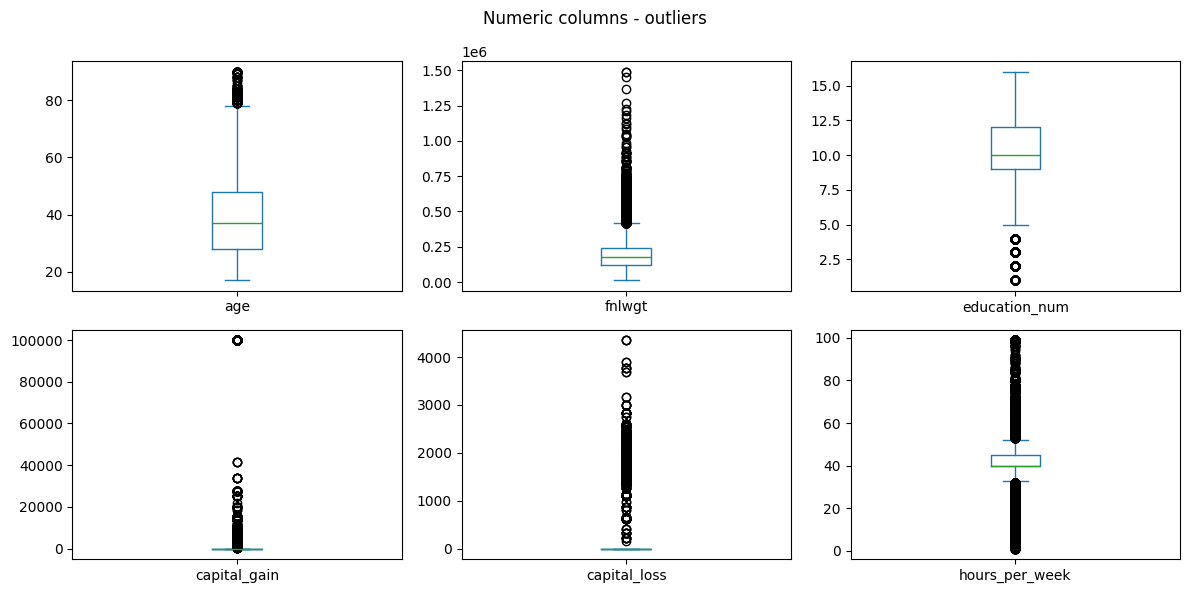

In [6]:
import matplotlib.pyplot as plt   # library for drawing charts

# One box plot per numeric column; dots beyond the whiskers are outliers.
# sharey=False gives each plot its own scale, because the columns
# have very different ranges (e.g. age vs capital_gain).
df[num_cols].plot(kind="box", subplots=True, layout=(2, 3),
                  figsize=(12, 6), sharey=False)
plt.suptitle("Numeric columns - outliers")
plt.tight_layout()   # stop the plots from overlapping
plt.show()

## 7. Size after cleaning (must be at least 3,000 rows and 7 columns)

In [7]:
# Simple cleaning for the size check:
# 1) drop rows that have any missing value
# 2) drop rows that are exact duplicates of another row
clean = df.dropna().drop_duplicates()

print(f"After cleaning: {clean.shape[0]:,} rows x {clean.shape[1]} columns")

# Check the brief's minimum size
meets = clean.shape[0] >= 3000 and clean.shape[1] >= 7
print("Meets brief:", "YES" if meets else "NO")

After cleaning: 45,175 rows x 15 columns
Meets brief: YES


## 8. Summary of the numbers (copy into the poster)

In [8]:
from IPython.display import Markdown, display   # show results as formatted text

# Build a markdown table from the real results of the cells above
lines = ["| Item | Value |", "|---|---|",
         f"| Raw rows | {df.shape[0]:,} |",
         f"| Raw columns | {df.shape[1]} |"]
for col, n in missing.items():                       # one line per column with missing values
    lines.append(f"| Missing in `{col}` | {n:,} ({n/len(df)*100:.2f}%) |")
lines += [f"| Rows with any missing value | {rows_with_missing:,} |",
          f"| Duplicate rows (after dropping missing) | {df.dropna().duplicated().sum():,} |",
          f"| Rows after cleaning | {clean.shape[0]:,} |",
          f"| Columns after cleaning | {clean.shape[1]} |"]
for col, n in outlier_counts.items():                # outliers per numeric column
    lines.append(f"| Outliers in `{col}` (IQR) | {n:,} |")

display(Markdown("\n".join(lines)))

| Item | Value |
|---|---|
| Raw rows | 48,842 |
| Raw columns | 15 |
| Missing in `workclass` | 2,799 (5.73%) |
| Missing in `occupation` | 2,809 (5.75%) |
| Missing in `native_country` | 857 (1.75%) |
| Rows with any missing value | 3,620 |
| Duplicate rows (after dropping missing) | 47 |
| Rows after cleaning | 45,175 |
| Columns after cleaning | 15 |
| Outliers in `age` (IQR) | 216 |
| Outliers in `fnlwgt` (IQR) | 1,453 |
| Outliers in `education_num` (IQR) | 1,794 |
| Outliers in `capital_gain` (IQR) | 4,035 |
| Outliers in `capital_loss` (IQR) | 2,282 |
| Outliers in `hours_per_week` (IQR) | 13,496 |

**Write your numbers here after running the notebook** (copy them from the table above):

- Raw rows: 48,842 , Raw columns: 15
- Missing values: workclass: 2,799 , occupation : 2,809, native_country: 857
- Rows after cleaning: 45,175

## 9. Source and Harvard reference
**Link:** https://archive.ics.uci.edu/dataset/2/adult

**Harvard reference (for the poster):**  
Becker, B. and Kohavi, R. (1996) *Adult* [Dataset]. UCI Machine Learning Repository. Available at: https://doi.org/10.24432/C5XW20 (Accessed: 17 November 2026).

In-text: (Becker and Kohavi, 1996)

## 10. Motivation
I chose the **Population and Society** domain because income inequality affects almost every country, including Pakistan. People often assume that education and hard work decide how much someone earns, but factors such as gender, race, marital status and type of job may also play a large part. I wanted to test these ideas with real data rather than opinion.

The **UCI Adult (Census Income)** dataset suits this goal well. It contains real records from the 1994 US Census for about 48,000 people, with a clear outcome (whether a person earns more than $50,000 a year) and a mix of personal and work details. It also has missing values and outliers, so it gives a realistic chance to practise data cleaning, and it has both text and numeric columns for encoding and PCA.

**Problem to explore:** Which demographic and employment factors are most strongly linked to earning more than $50K a year, and are there clear income gaps by gender, race or education level?

## 11. Download the CSV (for GitHub and Moodle)

In [9]:
# Download adult_raw.csv from Colab to your computer
from google.colab import files
files.download("adult_raw.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Upload the dataset to GitHub
1. Open your repository on github.com.
2. Click **Add file → Upload files**.
3. Choose `adult_raw.csv` (you can drag it into a `data/` folder).
4. Write a message such as *Add UCI Adult Census Income dataset* and click **Commit changes**. This counts as one of your 7 commits.